In [1]:
import numpy as np
import pandas as pd
from sklearn import *
import matplotlib.pyplot as plt

In [2]:
data = datasets.load_diabetes()

In [3]:
x = pd.DataFrame(data['data'], columns=data['feature_names'])
x['patient_id'] = np.arange(x.shape[0])
x['species'] = 1

y = data['target']
x['y'] = y   # Oops...

In [5]:
x

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,patient_id,species,y
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,0,1,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,1,1,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,2,1,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,3,1,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,4,1,135.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,437,1,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,438,1,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,439,1,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,440,1,220.0


In [6]:
x_train, x_test, y_train, y_test = model_selection.train_test_split(x, y, random_state=42)

In [12]:
columns = x.columns
columns = x.columns.difference({'y', 'species', 'patient_id'})
x_train = x_train[columns]
x_test = x_test[columns]
print(x_train)

          age       bmi        bp        s1        s2        s3        s4  \
16  -0.005515  0.042296  0.049415  0.024574 -0.023861  0.074412 -0.039493   
408  0.063504 -0.050396  0.107944  0.031454  0.019354 -0.017629  0.023608   
432  0.009016  0.055229 -0.005670  0.057597  0.044719 -0.002903  0.023239   
316  0.016281  0.014272  0.001215  0.001183 -0.021355 -0.032356  0.034309   
3   -0.089063 -0.011595 -0.036656  0.012191  0.024991 -0.036038  0.034309   
..        ...       ...       ...       ...       ...       ...       ...   
106 -0.096328 -0.076264 -0.043542 -0.045599 -0.034821  0.008142 -0.039493   
270  0.005383  0.030440  0.083844 -0.037344 -0.047347  0.015505 -0.039493   
348  0.030811 -0.020218 -0.005670 -0.004321 -0.029497  0.078093 -0.039493   
435 -0.012780 -0.023451 -0.040099 -0.016704  0.004636 -0.017629 -0.002592   
102 -0.092695  0.028284 -0.015999  0.036958  0.024991  0.056003 -0.039493   

           s5        s6       sex  
16   0.052277  0.027917 -0.044642  
408

0.47075113761587883


(35.05351782073925, 303.8243537212122)

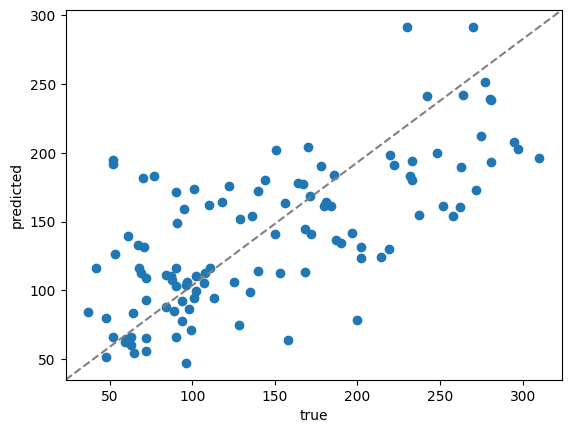

In [16]:
regressor = svm.SVR(**{'C': 1000, 'kernel': 'linear'})
# regressor = linear_model.LinearRegression()
regressor.fit(x_train, y_train)
y_hat = regressor.predict(x_test)
print(regressor.score(x_test, y_test))

plt.scatter(y_test, y_hat)
plt.xlabel('true')
plt.ylabel('predicted')
xlim = plt.xlim()
ylim = plt.ylim()
plt.plot(xlim, ylim, '--', c='grey')
plt.xlim(xlim)
plt.ylim(ylim)

0.475553721922382


(36.974189095838334, 282.3921347220534)

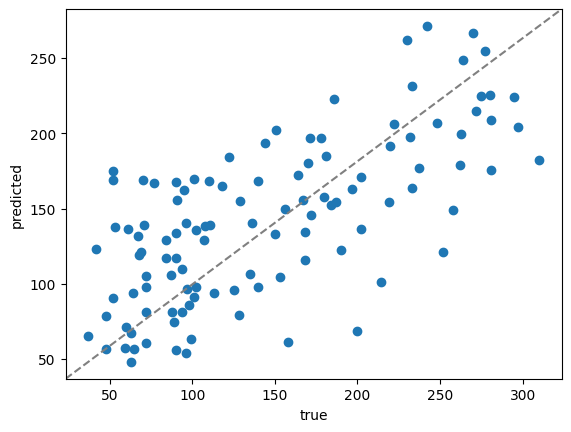

In [23]:
# selector = feature_selection.VarianceThreshold(threshold=0.001)
selector = feature_selection.SelectKBest(feature_selection.r_regression, k=4)
x_filtered = selector.fit_transform(x_train, y=y_train)
regressor.fit(x_filtered, y_train)

x_test_filtered = selector.transform(x_test)  # Not fit!
y_hat = regressor.predict(x_test_filtered)
print(regressor.score(x_test_filtered, y_test))

plt.scatter(y_test, y_hat)
plt.xlabel('true')
plt.ylabel('predicted')
xlim = plt.xlim()
ylim = plt.ylim()
plt.plot(xlim, ylim, '--', c='grey')
plt.xlim(xlim)
plt.ylim(ylim)

In [39]:
regressor = svm.SVR()
gcv = model_selection.GridSearchCV(
    regressor, [
        {
            'kernel': ['linear'],
            # 'C': [ 1e2, 1e3, 1e5, 1e7],
            'C': np.arange(100, 2100, 100),
        },
        # {
        #     'kernel': ['poly'],
        #     'degree': np.arange(1, 5),
        #     'gamma': ['auto', 'scale'],
        #     'coef0': [0, 1e-2, 1e-1, 1],
        #     'C': [1e-2, 1e-1, 1, 1e1, 1e2, 1e3],
        # },
        # {
        #     'kernel': ['sigmoid'],
        #     'gamma': ['auto', 'scale'],
        #     'coef0': [0, 1e-2, 1e-1, 1],
        #     'C': [1e-2, 1e-1, 1, 1e1, 1e2, 1e3],
        # },
        # {
        #     'kernel': ['rbf'],
        #     'gamma': ['auto', 'scale'],
        #     'C': [1e-2, 1e-1, 1, 1e1, 1e2, 1e3],
        # },
    ],
cv=4, n_jobs=8)
gcv.fit(x_train, y_train)
print(gcv.best_params_)
print(gcv.best_score_)

{'C': np.int64(700), 'kernel': 'linear'}
0.44397173187896527
